# Estimating Straylight with ROSALIA 

## What is this? 

The purpose of this notebook is to demonstrate the use of ROSALIA. First we will generate a custom ROSALIA exposure object, and then use the `rosalia.core.exposure.straylight()` method to estimate the expected stray-light background from out-of-field sources. The code will generate a series of summary plots (png images) and a background image stored as a FITS format. 

The tutorial is divided on three examples: 

    - Estimating stray-light on a mock observation generated by ROSALIA
    - Estimating stray-light on a real observation file

## How to start

To run this notebook, please activate the "rosalia" kernel at the top right of your window.

## Imports

- *rosalia* for Roman/WFI stray-light analysis
- *astropy.time* to determine the start of the observation. 
- *asdf* for accessing the ASDF Roman mock observations
- *s3fs* for accessing the S3 cloud files in the Nexus
- *os* for Python path processing 

In [1]:
import rosalia as rs
from astropy.time import Time

### 1 - Estimating stray-light from Vega in Roman/WFI illuminating the secondary mirror strut

> Synthetic Roman WFI exposure
2026-11-03T15:34:03.072953 > Fetching source catalog
find_mosaic_wcs: Loading existing catalog! Remove Vega_at_Secondary_leg_Roman_RA_283.757_DEC_044.260_MJD_61314.00000_PA_-181.73_source_catalog.csv if this is a mistake.
2026-11-03T15:34:03.600337 > Done.


18it [00:03,  5.20it/s]

2026-11-03T15:34:07.076964 > Starting Stray-light scan: 



100%|██████████| 18/18 [01:10<00:00,  3.90s/it]


2026-11-03T15:35:18.247221 > Done : 0:01:11.170282 elapsed.
 > Reconstructing the Stray-light / Main offender map: 
2026-11-03T15:35:19.297855 > Done : 
DATA / WCS mode
DATA / WCS mode
2026-11-03T15:35:27.611372 > Summary plots... 
Plot: Stray-light surface brightness magnitude.


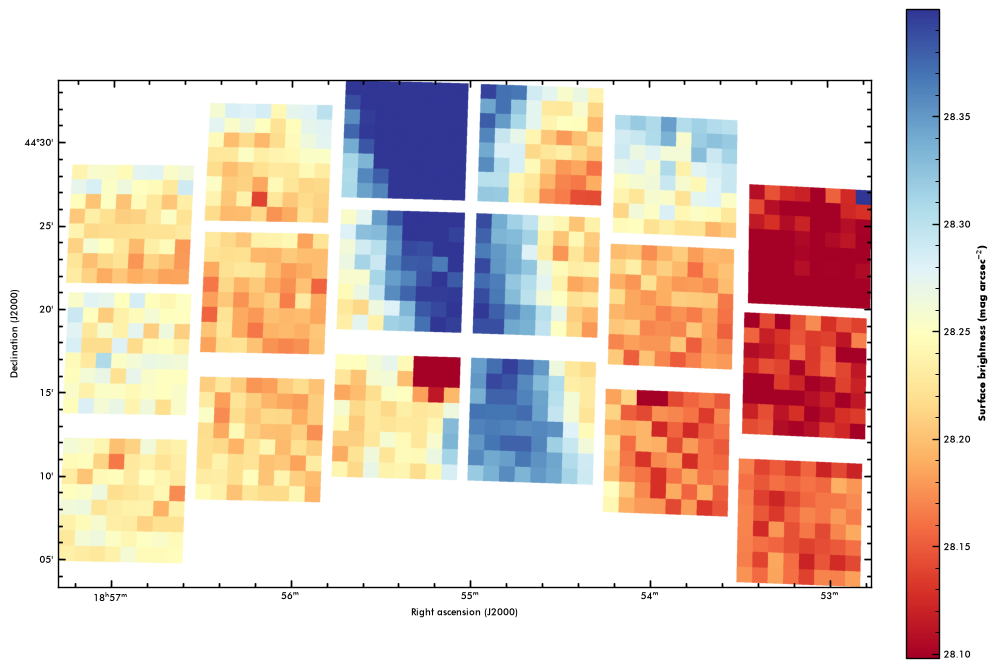

Plot: Stray-light surface brightness flux.


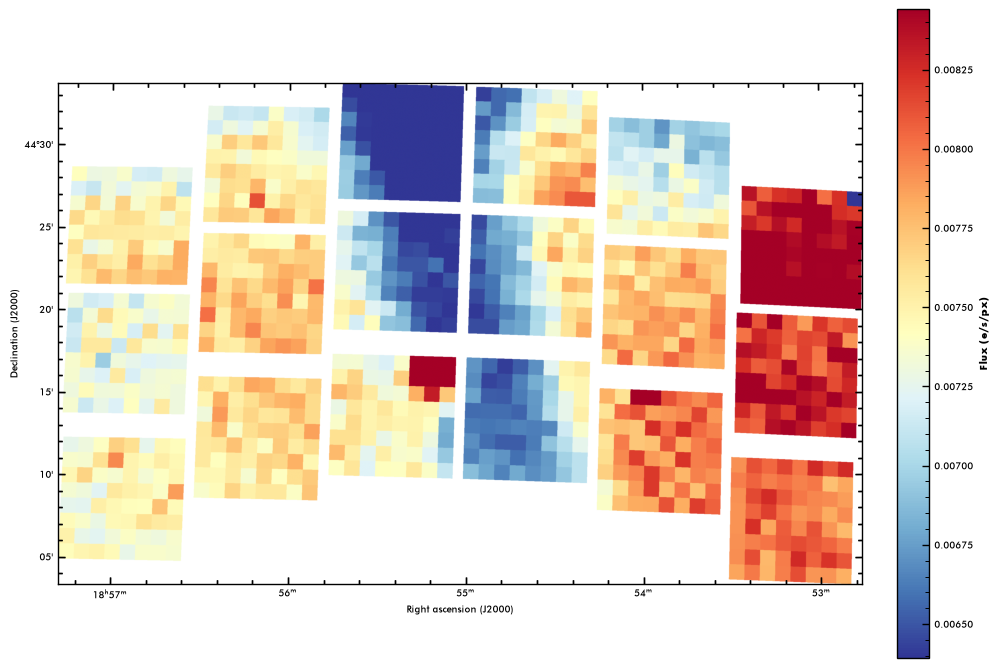

Plot: Main offender map.
Simbad query failed for 279.2341 - 38.782993. Skipping
Simbad query failed for 292.8516 - 43.503548. Skipping
Simbad query failed for 283.13657 - 44.4152. Skipping
Simbad query failed for 283.79053 - 44.29359. Skipping
Simbad query failed for 283.48907 - 44.260075. Skipping


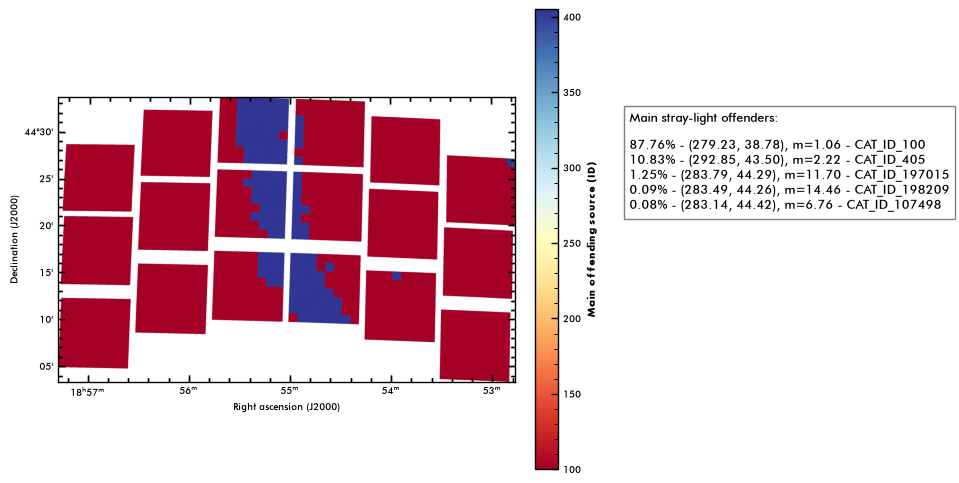

Plot: Source environment map.
0.6
SSO body: Sun not found. Skipping
SSO body: Moon not found. Skipping
SSO body: Earth not found. Skipping
SSO body: Mercury not found. Skipping
SSO body: Venus not found. Skipping
SSO body: Mars not found. Skipping
SSO body: Jupiter not found. Skipping
SSO body: Saturn not found. Skipping
SSO body: Uranus not found. Skipping
SSO body: Neptune not found. Skipping
SSO body: Pluto not found. Skipping


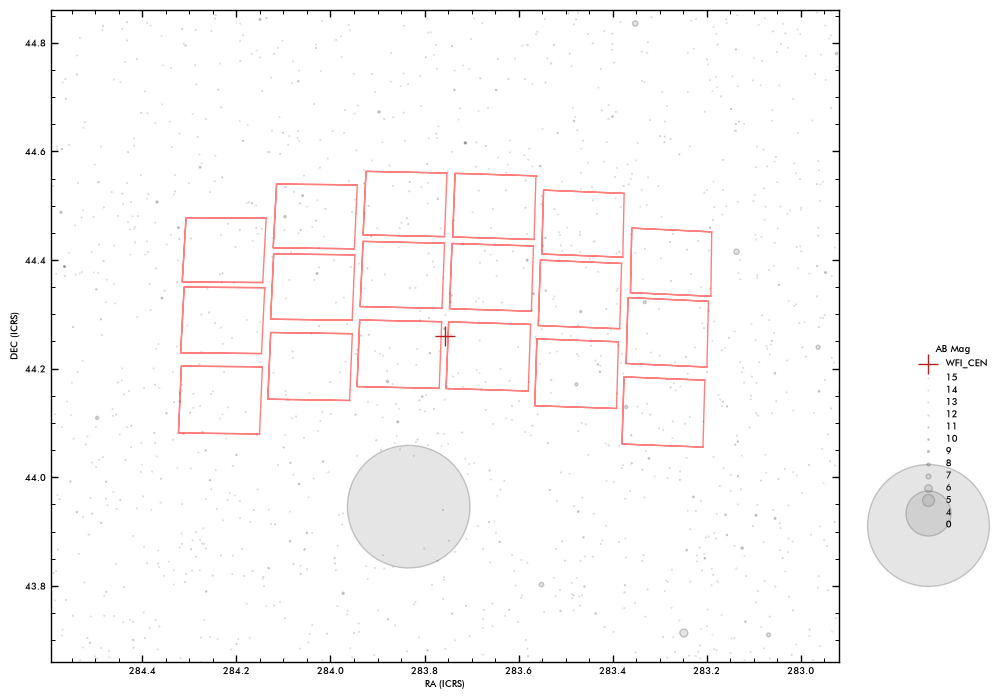

Plot: Location of Main offenders on NDI map.
Simbad query failed for 279.2341 - 38.782993. Skipping
Simbad query failed for 292.8516 - 43.503548. Skipping
Simbad query failed for 283.13657 - 44.4152. Skipping
Simbad query failed for 283.79053 - 44.29359. Skipping
Simbad query failed for 283.48907 - 44.260075. Skipping
0    6.437019
1    6.595288
3    0.041121
4    0.191771
2    0.469909
Name: dist, dtype: float32
6.925052690505982
2026-11-03T15:48:08.867387 > Done
Output saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/tutorials/Vega_at_Secondary_leg_Roman_RA_283.757_DEC_044.260_MJD_61314.00000_PA_-181.73_stray.fits
Report saved in: /Users/aborlaff/NASA/ROSALIA/notebooks/tutorials/Vega_at_Secondary_leg_Roman_RA_283.757_DEC_044.260_MJD_61314.00000_PA_-181.73_stray.pdf


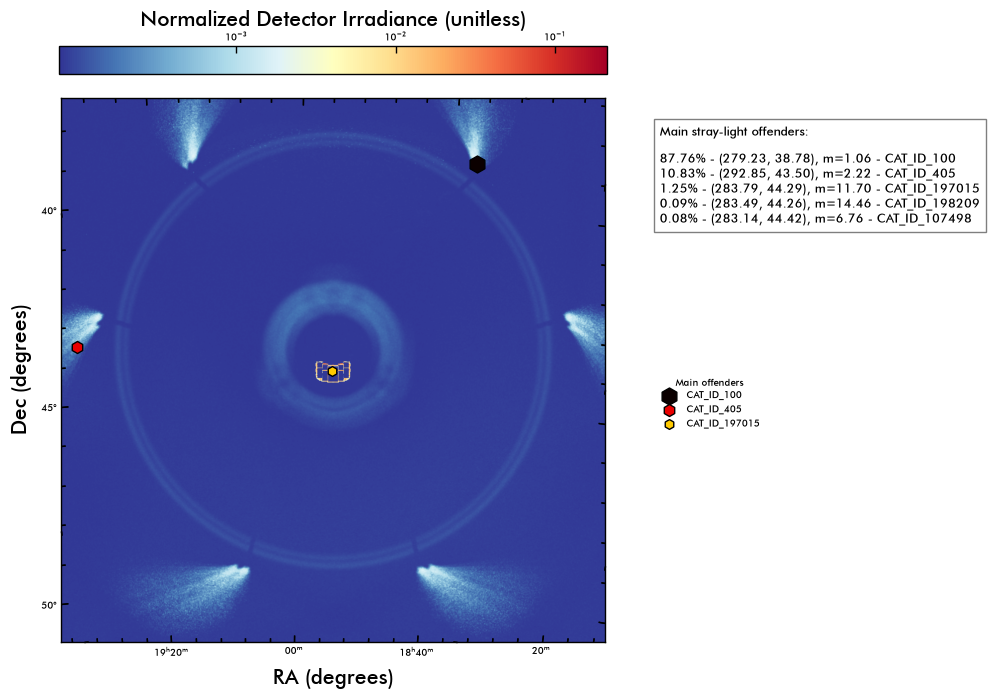

In [2]:
# This notebook demonstrates how to use ROSALIA to analyze stray light in a simple exposure. 

# Find the Calibration Stars. 
ra_vega = 279.2347348 
dec_vega = +38.7836890
date = Time('2026-11-08T00:00:00.0', format='isot', scale='utc')

offset_pointing = rs.telescopes.Roman.find_wfi_center_for_offset_target(ra_target=ra_vega, dec_target=dec_vega,
                                                                        mjd=date.mjd,
                                                                        dX=-3.7, dY=5.27)

ra_wfi = offset_pointing["ra_wficen"]
dec_wfi = offset_pointing["dec_wficen"]
WFIPA_off = offset_pointing["PA_WFI_offset"]
date = Time("2026-10-01T00:00:00") # Date of the observation, in Astropy Time YYYY-MM-DDTHH:MM:SS format.
bandpass = "F146"
exptime = 600 # Exposure time, in seconds.


observer={"TELESCOP": "Roman/WFI", 
          "pointing": [ra_wfi, dec_wfi], 
          "FILTER":bandpass, 
          "PA_Y": WFIPA_off, 
          "EXPSTART": date.mjd, 
          "EXPTIME": exptime}

prefix = "Vega_at_Secondary_leg"

# With this line we generate the exposure object. This is the first step in any ROSALIA analysis. 
custom_roman_exposure = rs.core.exposure(observer=observer, prefix=prefix) 
straylight_out = custom_roman_exposure.straylight()

### 2 - Estimating stray-light on a real observation file

In [3]:
# Here is a mock observation pre-generated by the Roman Team

# With this line we generate the exposure object. This is the first step in any ROSALIA analysis.
import glob  
input_flc = sorted(glob.glob("/Users/aborlaff/NASA/ROSALIA_DEPOT/MAST_2026-09-16T0933/MAST/Roman/r0102001002001005001_0004_wfi*_f158_cal.asdf"))
roman_exposure = rs.core.exposure(input_flc)



Retrieving exposure : 100%|██████████| 15/15 [00:03<00:00,  3.95it/s]

Currently estimated through pysiaf and quaternion. This is a temporary fix until MAST fixes the RA_TARG, DEC_TARG, PA keywords in the Roman/WFI fits files.


## About this Notebook

**Author:** Alejandro S. Borlaff - NASA Ames Research Center (Code S) - a.s.borlaff@nasa.gov 

**Updated on** September 18, 2026. 
**Last tested on** September 28, 2026. ROSALIA 1.3.2